<a href="https://colab.research.google.com/github/Aemilianus/Estudos/blob/main/MMM_Meridian_Baseline_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Testando o pacote do Meridian.
Rodar a célula a abaixo somente uma vez e, depois, reiniciar a sessão.

In [ ]:
%pip install --upgrade "google-meridian[colab,and-cuda,schema]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 125.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 81.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 617.2/617.2 kB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 919.5/919.5 kB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 129.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 33.7 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: natsort
    Found exist

In [ ]:
import meridian
import tensorflow as tf

print("Versão do Meridian:", meridian.__version__)
print("Versão do TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))

Versão do Meridian: 2.0.0
Versão do TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Importando a base de dados do repositório oficial do Meridian no GitHub.

In [ ]:
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/google/meridian/main/"
    "meridian/data/simulated_data/csv/geo_media.csv"
)

df = pd.read_csv(DATA_URL, parse_dates=["time"])

print("Dimensão:", df.shape)
display(df.head())

Dimensão: (3120, 15)


,geo,time,Channel0_impression,Channel1_impression,Channel2_impression,Channel3_impression,competitor_activity_score_control,sentiment_score_control,Channel0_spend,Channel1_spend,Channel2_spend,Channel3_spend,conversions,revenue_per_conversion,population
0,Geo0,2021-01-25,334723.0,835023.0,640496.0,1792866.0,-0.112432,-2.531220,3733.023,9338.7650,7171.030,20701.168,12623308.0,0.034714,847483.56
1,Geo0,2021-02-01,468612.0,1907143.0,2754715.0,2159610.0,-1.272784,0.136265,5226.230,21329.1840,30841.947,24935.744,15978182.0,0.034858,847483.56
2,Geo0,2021-02-08,1336626.0,1698215.0,0.0,934249.0,-0.121609,-0.867212,14906.820,18992.5660,0.000,10787.223,16628105.0,0.034741,847483.56
3,Geo0,2021-02-15,1212772.0,393463.0,1150178.0,1830576.0,-0.481325,2.401830,13525.529,4400.4277,12877.459,21136.582,21324220.0,0.034595,847483.56
4,Geo0,2021-02-22,2364579.0,2119085.0,1147785.0,1324994.0,-3.065784,2.298567,26371.143,23699.5100,12850.667,15298.925,16610399.0,0.034669,847483.56


Confirmando a granularidade da base (agregações): Geolocalização, semanas, datas e verificando se existe alguma duplicidade de geo+data.

In [ ]:
print("Número de geos:", df["geo"].nunique())
print("Número de semanas:", df["time"].nunique())
print("Data Min:", df["time"].min())
print("Data Max:", df["time"].max())

print("Número de duplicidades de geo+data:",
      df.duplicated(subset=["geo", "time"]).sum()
)

Número de geos: 20
Número de semanas: 156
Data Min: 2021-01-25 00:00:00
Data Max: 2024-01-15 00:00:00
Número de duplicidades de geo+data: 0


O Meridian precisa do formato WIDE para funcionar. Como a base já vem nesse formato, não precisamos alterar. Contudo, caso não venha, é necessário fazê-lo.

O Meridian Utiliza formato **`xarray`** e existe uma função para facilitar a criação da estrutura dos dados:

`DataFrameInputDataBuilder`

Precisa-se tomar o cuidado de colocar todas as variáveis nas mesmas posições (índices) nas listas, pois a relação é pareada 1:1, exceção da lista de variáveis controle

In [ ]:
# Variável resposta do modelo

COLUNA_KPI = "conversions" #Coluna com o número de conversões associadas ao canal

# Valor financeiro associado a uma unidade do KPI
COLUNA_RECEITA_POR_KPI = "revenue_per_conversion"

# Execuções de mídias
COLUNAS_MIDIA = [
    "Channel0_impression",
    "Channel1_impression",
    "Channel2_impression",
    "Channel3_impression"
]

# Investimento em cada mídia
COLUNAS_INVESTIMENTO = [
    "Channel0_spend",
    "Channel1_spend",
    "Channel2_spend",
    "Channel3_spend"
]

# Nomes de Caption (que aparecerão nos resultados)
NOMES_CANAIS = [
    "Channel0",
    "Channel1",
    "Channel2",
    "Channel3"
]

# Variáveis de controle se existirem. Aqui entram regressoras externar às mídias
COLUNAS_CONTROLE = [
    "competitor_activity_score_control",
    "sentiment_score_control"
]

Importando a função do módulo. Assim funciona melhor, ao tentar escrever módulo.função o colab deu erro. Então importar a função do módulo é mais garantido.

In [ ]:
from meridian.data.data_frame_input_data_builder import (
    DataFrameInputDataBuilder,
)

Craindo o formato com a função.

In [ ]:
construtor = DataFrameInputDataBuilder(
    kpi_type = "non_revenue",
    default_kpi_column = COLUNA_KPI,
    default_revenue_per_kpi_column = COLUNA_RECEITA_POR_KPI
    )

print(construtor)

Adicionando, agora, o KPI

In [ ]:
construtor = construtor.with_kpi(df)

A função do construtor automaticamente identifica as colunas "geo" e "time", mas se tiverem nomes diferentes, precisaríamos passar os argumentos `geo_col` e `time_col` com seus nomes em character.

In [ ]:
# Checando as colunas do construtor
print(construtor.kpi.dims)
print(construtor.kpi.shape)

# Temos as duas dimensões de geolocalização e data, com 20 regiões e 156
# semanas.


('geo', 'time')
(20, 156)


Agora, adicionamos as colunas de revenue_per_conversions que foi declarada anteriormente como a coluna de revenue atrelada ao KPI e também a coluna de população, que não foi declarada, mas o Meridian por default procura *population*.

A coluna de revenue não é uma regressora, mas sim uma coluna com valores que, após a modelagem, será utilizada para converter o incremento das conversões em receita e ROI.
Já a coluna de população, ajuda a comparar regiões com populações diferentes.
**Porém existe uma limitação importante:
O Meridian assume população constante no tempo, permitindo mudanças apenas geolocalizadas. Um modelo de Poisson absorve isso naturalmente com o uso de um termo offset.**

O Meridian assume a população constante ao longo de todo o tempo t.


In [ ]:
construtor = construtor.with_revenue_per_kpi(df)
construtor = construtor.with_population(df)

In [ ]:
print(construtor.revenue_per_kpi.dims)
print(construtor.revenue_per_kpi.shape)

print(construtor.population.dims)
print(construtor.population.shape)

('geo', 'time')
(20, 156)
('geo',)
(20,)


Agora, adicionamos as variáveis de **controle**

In [ ]:


construtor = construtor.with_controls(
    df=df,
    control_cols = COLUNAS_CONTROLE
)

In [ ]:
# Checando o que foi criado
print("Dimensões:", construtor.controls.dims)
print("Formato:", construtor.controls.shape)
print("Controles:",
      construtor.controls.coords["control_variable"].values)

Dimensões: ('geo', 'time', 'control_variable')
Formato: (20, 156, 2)
Controles: ['competitor_activity_score_control' 'sentiment_score_control']


Adicionando, por fim, as colunas de mídias e investimentos

In [ ]:
construtor = construtor.with_media(
    df=df,
    media_cols=COLUNAS_MIDIA,
    media_spend_cols=COLUNAS_INVESTIMENTO,
    media_channels=NOMES_CANAIS
)

In [ ]:
# Checando se tudo foi criado corretamente:

print("KPI: ", construtor.kpi is not None)
print("Revenue per KPI: ", construtor.revenue_per_kpi is not None)
print("Population: ", construtor.population is not None)
print("Controls: ", construtor.controls is not None)
print("Mídia: ", construtor.media is not None)
print("Investimento: ", construtor.media_spend is not None)

KPI:  True
Revenue per KPI:  True
Population:  True
Controls:  True
Mídia:  True
Investimento:  True


Toda a estrutura foi adicionada, podemos construir o objeto final.

A propriedade `.build()` confere se todas as dimensões estão corretas e os canais coerentes.

In [ ]:
dados_meridian = construtor.build()
print(type(dados_meridian))

<class 'meridian.data.input_data.InputData'>


Vamos declarar as hipóteses do modelo












In [ ]:
# Melhor importar as funções antes

from meridian.model import model
from meridian.model import prior_distribution
from meridian.model import spec

In [ ]:
especificacao = spec.ModelSpec(
    #Prioris padrões do Meridian
    prior = prior_distribution.PriorDistribution(),
    #Efeitos apenas positivos para as mídias
    media_effects_dist = "log_normal",
    #primeiro aplica o adstock (memória) e depois saturação
    hill_before_adstock = False,
    # Até 8 semanas de defasagem
    max_lag = 8,
    # Único valor para aa variância entre as geos
    unique_sigma_for_each_geo = False,
    # Parametriza a priori de mídia por ROI, usando a revenue_per_conversion
    media_prior_type = "roi",
    #Decaimento geométrico para o esquecimento
    adstock_decay_spec = "geometric",
    # Automatic Knots Selection: Utiliza as geos para estimar
    # um valor médio temporal (a cada tempo t). Os knots são as semenas em que
    # a méida baseline pode mudar, capturando tendência e sazonalidades.
    enable_aks = False,

)

In [ ]:
# Montando o modelo com os dados

modelo_meridian = model.Meridian(
    input_data=dados_meridian,
    model_spec=especificacao
)

Posteriori

In [ ]:
%%time

modelo_meridian.sample_prior(200)

modelo_meridian.sample_posterior(
    n_chains = 4,
    n_adapt = 500,
    n_burnin = 300,
    n_keep = 500,
    seed = 123
)

CPU times: user 13min 21s, sys: 3.23 s, total: 13min 24s
Wall time: 13min 26s


/usr/local/lib/python3.13/dist-packages/arviz/data/inference_data.py:157: UserWarning: trace group is not defined in the InferenceData scheme
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/arviz/data/inference_data.py:1647: UserWarning: trace group is not defined in the InferenceData scheme
  warnings.warn(


In [ ]:
from google.colab import drive
from meridian.schema.serde import meridian_serde
drive.mount("/content/drive")
caminho = "/content/drive/MyDrive/MMM/modelo_meridian_baseline.binpb"
meridian_serde.save_meridian(modelo_meridian, caminho)
print("salvo em", caminho)
print(modelo_meridian.inference_data.groups()) # deve ter prior e posterior

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import arviz as az
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

resumo_posterior = az.summary(
    modelo_meridian.inference_data,
    group="posterior",
    var_names=["roi_m","alpha_m","ec_m","sigma"]
)

display(resumo_posterior)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
roi_m[Channel0],2.695,0.345,2.132,3.418,0.012,0.009,790.0,1040.0,1.01
roi_m[Channel1],1.591,0.235,1.192,2.050,0.011,0.009,616.0,889.0,1.02
roi_m[Channel2],3.678,0.668,2.566,4.917,0.071,0.051,90.0,454.0,1.04
roi_m[Channel3],1.958,0.373,1.365,2.697,0.034,0.024,113.0,410.0,1.04
alpha_m[Channel0],0.393,0.040,0.313,0.461,0.001,0.001,1527.0,1428.0,1.00
alpha_m[Channel1],0.274,0.058,0.167,0.383,0.001,0.001,1512.0,1378.0,1.00
alpha_m[Channel2],0.455,0.044,0.374,0.538,0.001,0.001,920.0,1541.0,1.01
alpha_m[Channel3],0.227,0.056,0.125,0.336,0.002,0.002,622.0,1362.0,1.01
ec_m[Channel0],1.542,0.414,0.864,2.372,0.013,0.009,999.0,1348.0,1.01
ec_m[Channel1],1.697,0.503,0.846,2.670,0.013,0.009,1452.0,1327.0,1.00


In [ ]:
from meridian.analysis import analyzer

analisador = analyzer.Analyzer(model_context= modelo_meridian.model_context,
                               inference_data= modelo_meridian.inference_data)

mu_posterior = analisador.expected_outcome(
    use_posterior = True,
    aggregate_geos = False,
    aggregate_times = False,
    inverse_transform_outcome = True,
    use_kpi = True,
    batch_size = 100
)

mu_posterior = np.array(mu_posterior)

print("Amostras: ", mu_posterior.shape)

Amostras:  (4, 500, 20, 156)


Calcular a média posteriori

In [ ]:
# μ̂_gt = média da posterior sobre cadeias (eixo 0) e draws (eixo 1).
# mu_posterior.shape = (n_chains, n_keep, n_geos, n_times) = (4, 500, 20, 156)
mu_meridian = mu_posterior.mean(axis=(0, 1))

print("μ̂ (geo × tempo):", mu_meridian.shape)

y_obs = np.asarray(dados_meridian.kpi)
print("KPI observado:", y_obs.shape)
print("Média de μ̂:", float(np.mean(mu_meridian)))
print("Média de y:", float(np.mean(y_obs)))

μ̂ (geo × tempo): (20, 156)
KPI observado: (20, 156)
Média de μ̂: 10442974.921058884
Média de y: 10442706.212051282


Alguns diagnósticos

In [ ]:


import numpy as np
import pandas as pd

y_observado = np.asarray(dados_meridian.kpi.values)
mu_estimado = np.asarray(mu_meridian)

residuos = y_observado - mu_estimado

rmse = np.sqrt(np.mean(residuos**2))
mae = np.mean(np.abs(residuos))
wmape = np.sum(np.abs(residuos)) / np.sum(np.abs(y_observado))

r2 = 1 - (
    np.sum(residuos**2)
    / np.sum((y_observado - y_observado.mean())**2)
)

pd.DataFrame({
    "metrica": ["Média observada", "Média estimada", "RMSE", "MAE", "wMAPE", "R²"],
    "valor": [
        y_observado.mean(),
        mu_estimado.mean(),
        rmse,
        mae,
        wmape,
        r2,
    ],
})

,metrica,valor
0,Média observada,1.044271e+07
1,Média estimada,1.044297e+07
2,RMSE,2.970840e+05
3,MAE,2.151226e+05
4,wMAPE,2.060027e-02
5,R²,9.974657e-01


In [ ]:
print("Mínimo de mu:", mu_estimado.min())
print("Máximo de mu:", mu_estimado.max())
print("Quantidade não positiva:", np.sum(mu_estimado <= 0))

Mínimo de mu: -397771.4822240502
Máximo de mu: 33972966.88285598
Quantidade não positiva: 1


Mesmo com todos as observações positivas, ainda uma céulua teve média esperada menor que 0.Irei substituir esse valor pela média, apenas para não ter um valor negativo na hora de amostrar da Poisson.

In [ ]:
import numpy as np
import pandas as pd

# ==============================================================================
# 1. IDENTIFICAÇÃO E TABULAÇÃO DAS CÉLULAS PROBLEMÁTICAS (mu <= 0)
# ==============================================================================
indices_problematicos = np.argwhere(mu_estimado <= 0)

geos = dados_meridian.kpi.coords["geo"].values
tempos = pd.to_datetime(dados_meridian.kpi.coords["time"].values)

problemas = []
for indice_geo, indice_tempo in indices_problematicos:
    problemas.append(
        {
            "indice_geo": indice_geo,
            "indice_tempo": indice_tempo,
            "geo": geos[indice_geo],
            "time": tempos[indice_tempo],
            "mu_estimado": mu_estimado[indice_geo, indice_tempo],
            "y_observado": y_observado[indice_geo, indice_tempo],
        }
    )

df_problemas = pd.DataFrame(problemas)
display(df_problemas)


# ==============================================================================
# 2. DIAGNÓSTICO DA POSTERIOR COMPLETA DAS CÉLULAS IDENTIFICADAS
# ==============================================================================
# Examina toda a densidade posterior mu_posterior (draws/chains, geo, tempo)
print("--- Diagnóstico da Posterior para Células com Média <= 0 ---")
for indice_geo, indice_tempo in indices_problematicos:
    draws_celula = mu_posterior[:, :, indice_geo, indice_tempo].flatten()

    media_post = np.mean(draws_celula)
    prob_nao_positiva = np.mean(draws_celula <= 0)
    q025, q50, q975 = np.quantile(draws_celula, [0.025, 0.5, 0.975])

    print(f"\nGeo: {geos[indice_geo]} | Tempo: {tempos[indice_tempo]}")
    print(f"  Média posterior:                      {media_post:.6f}")
    print(f"  P(mu <= 0):                           {prob_nao_positiva * 100:.2f}%")
    print(f"  Intervalo crível (2.5%, 50%, 97.5%):  [{q025:.6f}, {q50:.6f}, {q975:.6f}]")


# ==============================================================================
# 3. TRATAMENTO EXPLORATÓRIO PARA SIMULAÇÃO POISSON (lambda > 0)
# ==============================================================================
# Para Poisson, lambda_g,t > 0 é estritamente obrigatório.
# Substituição pontual pelo menor valor positivo observado na matriz mu_estimado.
mu_positivo = mu_estimado.copy()
menor_positivo = mu_estimado[mu_estimado > 0].min()

celulas_ajustadas = np.sum(mu_estimado <= 0)
mu_positivo[mu_positivo <= 0] = menor_positivo

print("\n--- Validação do Ajuste ---")
print(f"Células substituídas:        {celulas_ajustadas}")
print(f"Menor valor antes do ajuste: {mu_estimado.min():.6f}")
print(f"Menor valor após o ajuste:   {mu_positivo.min():.6f}")




,indice_geo,indice_tempo,geo,time,mu_estimado,y_observado
0,4,32,Geo4,2021-09-06,-397771.482224,1293408.8


--- Diagnóstico da Posterior para Células com Média <= 0 ---

Geo: Geo4 | Tempo: 2021-09-06 00:00:00
  Média posterior:                      -397771.482224
  P(mu <= 0):                           100.00%
  Intervalo crível (2.5%, 50%, 97.5%):  [-525788.664532, -396243.108162, -276002.503936]

--- Validação do Ajuste ---
Células substituídas:        1
Menor valor antes do ajuste: -397771.482224
Menor valor após o ajuste:   407431.659989


In [ ]:
forma_relativa = mu_positivo / mu_positivo.mean()


In [ ]:
medias_alvo = [1,2, 5, 10, 25, 50]

lambdas = {}
contagens_simuladas = {}

for media_alvo in medias_alvo:
    lambda_gt = media_alvo * forma_relativa
    gerador = np.random.default_rng(seed=123 + media_alvo)
    y_simulado = gerador.poisson(lambda_gt)

    lambdas[media_alvo] = lambda_gt
    contagens_simuladas[media_alvo] = y_simulado

Checando se foi tudo certo. Parece que a simulação funcionou e alguns zeros apareceram durante o processo, o que era esperado para lambdas menores.

In [ ]:
resumo_simulacao = []

for media_alvo in medias_alvo:
    lambda_gt = lambdas[media_alvo]
    y_simulado = contagens_simuladas[media_alvo]

    resumo_simulacao.append(
        {
            "media_alvo": media_alvo,
            "media_lambda": lambda_gt.mean(),
            "media_observada": y_simulado.mean(),
            "minimo": y_simulado.min(),
            "maximo": y_simulado.max(),
            "percentual_zeros": 100 * np.mean(y_simulado == 0),
        }
    )

resumo_simulacao = pd.DataFrame(resumo_simulacao)
display(resumo_simulacao)

,media_alvo,media_lambda,media_observada,minimo,maximo,percentual_zeros
0,1,1.0,1.011859,0,8,40.993590
1,2,2.0,1.971474,0,11,22.756410
2,5,5.0,4.930128,0,22,5.064103
3,10,10.0,10.044872,0,38,1.250000
4,25,25.0,25.180449,0,87,0.032051
5,50,50.0,49.991667,2,153,0.000000


Montando a tabela com os dados origianis de média, contagem, tempo e geo.

In [ ]:
import numpy as np
import pandas as pd

MEDIA_ESCOLHIDA = 2

geos = dados_meridian.kpi.coords["geo"].values
tempos = pd.to_datetime(dados_meridian.kpi.coords["time"].values)

grade_geo_tempo = pd.MultiIndex.from_product(
    [geos, tempos],
    names=["geo", "time"],
).to_frame(index=False)

grade_geo_tempo["lambda_verdadeiro"] = lambdas[MEDIA_ESCOLHIDA].reshape(-1)
grade_geo_tempo["y_contagem"] = contagens_simuladas[MEDIA_ESCOLHIDA].reshape(-1)

In [ ]:
df_modelagem = df.copy()
df_modelagem["time"] = pd.to_datetime(df_modelagem["time"])

base_glm = grade_geo_tempo.merge(
    df_modelagem,
    on=["geo", "time"],
    how="left",
    validate="one_to_one",
)

print("Dimensão:", base_glm.shape)
print("Duplicidades geo-tempo:", base_glm.duplicated(["geo", "time"]).sum())
print("Média do lambda verdadeiro:", base_glm["lambda_verdadeiro"].mean())
print("Média da contagem observada:", base_glm["y_contagem"].mean())
print("Quantidade de valores ausentes:", base_glm.isna().sum().sum())

Dimensão: (3120, 17)
Duplicidades geo-tempo: 0
Média do lambda verdadeiro: 2.0
Média da contagem observada: 1.971474358974359
Quantidade de valores ausentes: 0


Agora, com a base_glm montada. Irei ajustar um modelo Poisson com os canais de mídia e controle:
```
# Execuções de mídias
COLUNAS_MIDIA = [
    "Channel0_impression",
    "Channel1_impression",
    "Channel2_impression",
    "Channel3_impression"
]

# Variáveis de controle se existirem. Aqui entram regressoras externar às mídias
COLUNAS_CONTROLE = [
    "competitor_activity_score_control",
    "sentiment_score_control"
]

```
As variáveis de adstock e Hill (Esquecimento e saturação) serão depois. Vamos começar com um modelo mais simples.

As variáveis de controle foram padronizadas ( $N~(0,1)$ ) pois estão em dimensões diferentes.

In [ ]:
# @title
PREDITORES_CONTINUOS = COLUNAS_MIDIA + COLUNAS_CONTROLE

PREDITORES_PADRONIZADOS = []

for coluna in PREDITORES_CONTINUOS:
    media_coluna = base_glm[coluna].mean()
    desvio_coluna = base_glm[coluna].std()

    if desvio_coluna == 0:
        raise ValueError(f"A coluna {coluna} não possui variação.")

    nova_coluna = "z_" + coluna
    base_glm[nova_coluna] = (base_glm[coluna] - media_coluna) / desvio_coluna
    PREDITORES_PADRONIZADOS.append(nova_coluna)

O modelo Poisson:

$ Y_{g,t} \sim \operatorname{Poisson}(\mu_{g,t})$ ,

$ \log\mu_{g,t} = \beta_0 + \sum_m\beta_m x_{g,t,m} + \sum_j\gamma_jz_{g,t,j} + a_g+d_t$ .

Os dois últimos termos são os controles categóricos para os efeitos de localização e tempo.

In [ ]:

formula_poisson = (
    "y_contagem ~ "
    + " + ".join(PREDITORES_PADRONIZADOS)
    + " + C(geo)"
    + " + C(time)" #Informando ao statsmodels que serão categóricas
)

print(formula_poisson)

y_contagem ~ z_Channel0_impression + z_Channel1_impression + z_Channel2_impression + z_Channel3_impression + z_competitor_activity_score_control + z_sentiment_score_control + C(geo) + C(time)


Ajustando o modelo

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

modelo_poisson = smf.glm(
    formula=formula_poisson,
    data=base_glm,
    family=sm.families.Poisson(),
).fit(maxiter=200)

print("Convergiu:", modelo_poisson.converged)

Convergiu: True


Como localização e tempo foram modeladas como categorias, centenas de preditores aparecem no summary. Analizei aqui somente os preditores padronizados

In [ ]:
intervalos = modelo_poisson.conf_int()

tabela_poisson = pd.DataFrame(
    {
        "coeficiente": modelo_poisson.params,
        "erro_padrao": modelo_poisson.bse,
        "p_valor": modelo_poisson.pvalues,
        "limite_inferior": intervalos[0],
        "limite_superior": intervalos[1],
    }
)

tabela_poisson = tabela_poisson.loc[PREDITORES_PADRONIZADOS]

tabela_poisson["razao_de_taxas"] = np.exp(tabela_poisson["coeficiente"])
tabela_poisson["rr_limite_inferior"] = np.exp(tabela_poisson["limite_inferior"])
tabela_poisson["rr_limite_superior"] = np.exp(tabela_poisson["limite_superior"])

display(tabela_poisson)

,coeficiente,erro_padrao,p_valor,limite_inferior,limite_superior,razao_de_taxas,rr_limite_inferior,rr_limite_superior
z_Channel0_impression,0.027684,0.020176,1.700238e-01,-0.011860,0.067228,1.028071,0.988210,1.069539
z_Channel1_impression,0.037759,0.020656,6.755316e-02,-0.002726,0.078244,1.038481,0.997277,1.081386
z_Channel2_impression,0.018141,0.020007,3.645327e-01,-0.021071,0.057354,1.018307,0.979149,1.059030
z_Channel3_impression,-0.011162,0.023198,6.304008e-01,-0.056630,0.034306,0.988900,0.944944,1.034901
z_competitor_activity_score_control,0.121861,0.013225,3.130039e-20,0.095940,0.147781,1.129597,1.100693,1.159259
z_sentiment_score_control,0.228823,0.013536,4.151725e-64,0.202293,0.255353,1.257119,1.224206,1.290917


Obtendo as médias estimadas

In [ ]:
base_glm["mu_poisson"] = modelo_poisson.predict(base_glm)

print(base_glm[["lambda_verdadeiro", "mu_poisson"]].describe())

       lambda_verdadeiro   mu_poisson
count        3120.000000  3120.000000
mean            2.000000     1.971474
std             1.128720     1.176859
min             0.078028     0.176463
25%             1.106985     1.076208
50%             1.748508     1.709038
75%             2.731858     2.611526
max             6.506216     7.547175


Agora, ajustando um modelo normal.

$Y_{g,t}=X_{g,t}\beta+\varepsilon_{g,t},\qquad\varepsilon_{g,t}\sim N(0,\sigma^2)$

In [ ]:
# Utilizando a mesma estrutura Poisson, mas fazendo o modelo normal.

modelo_normal = smf.ols(
    formula=formula_poisson,
    data=base_glm,
).fit()

base_glm["mu_normal"] = modelo_normal.predict(base_glm)

print(
    base_glm[
        [
            "lambda_verdadeiro",
            "mu_poisson",
            "mu_normal",
        ]
    ].describe()
)

       lambda_verdadeiro   mu_poisson    mu_normal
count        3120.000000  3120.000000  3120.000000
mean            2.000000     1.971474     1.971474
std             1.128720     1.176859     1.131911
min             0.078028     0.176463    -1.128631
25%             1.106985     1.076208     1.133001
50%             1.748508     1.709038     1.876381
75%             2.731858     2.611526     2.783733
max             6.506216     7.547175     5.319436


Comparando o modelo Poisson com o Normal

In [ ]:
def calcular_metricas(nome_modelo, previsao):
    verdadeiro = base_glm["lambda_verdadeiro"]
    erro = previsao - verdadeiro

    return {
        "modelo": nome_modelo,
        "media_prevista": previsao.mean(),
        "vies": erro.mean(),
        "mae_lambda": np.mean(np.abs(erro)),
        "rmse_lambda": np.sqrt(np.mean(erro**2)),
        "correlacao_lambda": np.corrcoef(previsao, verdadeiro)[0, 1],
        "minimo_previsto": previsao.min(),
        "maximo_previsto": previsao.max(),
        "quantidade_negativos": np.sum(previsao < 0),
        "percentual_negativos": 100 * np.mean(previsao < 0),
    }


comparacao_modelos = pd.DataFrame(
    [
        calcular_metricas("Poisson", base_glm["mu_poisson"]),
        calcular_metricas("Normal", base_glm["mu_normal"]),
    ]
)

display(comparacao_modelos)

,modelo,media_prevista,vies,mae_lambda,rmse_lambda,correlacao_lambda,minimo_previsto,maximo_previsto,quantidade_negativos,percentual_negativos
0,Poisson,1.971474,-0.028526,0.276250,0.394917,0.942455,0.176463,7.547175,0,0.000000
1,Normal,1.971474,-0.028526,0.318733,0.407815,0.935214,-1.128631,5.319436,75,2.403846


Poisson foi ligeiramente melhor e não produziu médias negativas. Mas isso pode ser simplesmente efeito da ligação log. Irei ajustar um modelo lg-normal e ver se os resultados se aproximam mais.

In [ ]:
modelo_normal_log = smf.glm(
    formula=formula_poisson,
    data=base_glm,
    family=sm.families.Gaussian(link=sm.families.links.Log()),
).fit(maxiter=200)

base_glm["mu_normal_log"] = modelo_normal_log.predict(base_glm)

print("Convergiu:", modelo_normal_log.converged)

Convergiu: True


In [ ]:
comparacao_tres_modelos = pd.DataFrame(
    [
        calcular_metricas(
            "Poisson com link log",
            base_glm["mu_poisson"],
        ),
        calcular_metricas(
            "Normal com link identidade",
            base_glm["mu_normal"],
        ),
        calcular_metricas(
            "Normal com link log",
            base_glm["mu_normal_log"],
        ),
    ]
)

display(comparacao_tres_modelos)

,modelo,media_prevista,vies,mae_lambda,rmse_lambda,correlacao_lambda,minimo_previsto,maximo_previsto,quantidade_negativos,percentual_negativos
0,Poisson com link log,1.971474,-0.028526,0.276250,0.394917,0.942455,0.176463,7.547175,0,0.000000
1,Normal com link identidade,1.971474,-0.028526,0.318733,0.407815,0.935214,-1.128631,5.319436,75,2.403846
2,Normal com link log,1.970656,-0.029344,0.292797,0.408281,0.937429,0.162438,7.320917,0,0.000000


O cenário com lambda 2 era o mais difícil, pois a diferença para o modelo normal tende a diminuir conforme lambda aumenta. Irei repetir numa função em looping com todoas as médias para observar as diferenças ficando cada vez menores.

In [ ]:
# Função com o cálculo das métricas

def calcular_metricas_cenario(
    media_alvo,
    nome_modelo,
    lambda_verdadeiro,
    previsao,
    dispersao=np.nan,
):
    erro = previsao - lambda_verdadeiro

    return {
        "media_alvo": media_alvo,
        "modelo": nome_modelo,
        "media_prevista": previsao.mean(),
        "vies": erro.mean(),
        "mae_lambda": np.mean(np.abs(erro)),
        "rmse_lambda": np.sqrt(np.mean(erro**2)),
        "correlacao_lambda": np.corrcoef(previsao, lambda_verdadeiro)[0, 1],
        "minimo_previsto": previsao.min(),
        "maximo_previsto": previsao.max(),
        "quantidade_negativos": np.sum(previsao < 0),
        "percentual_negativos": 100 * np.mean(previsao < 0),
        "dispersao_pearson": dispersao,
    }

In [ ]:
# Ajustes dos 3 modelos para cada uma das médias no vetor de lambdas reais.

resultados_cenarios = []

for media_alvo in medias_alvo:
    base_cenario = base_glm.copy()
    base_cenario["lambda_verdadeiro"] = lambdas[media_alvo].reshape(-1)
    base_cenario["y_contagem"] = contagens_simuladas[media_alvo].reshape(-1)

    # Poisson com link log
    ajuste_poisson = smf.glm(
        formula=formula_poisson,
        data=base_cenario,
        family=sm.families.Poisson(),
    ).fit(maxiter=200)

    pred_poisson = ajuste_poisson.predict(base_cenario)
    dispersao = ajuste_poisson.pearson_chi2 / ajuste_poisson.df_resid

    # Normal com link identidade
    ajuste_normal = smf.ols(
        formula=formula_poisson,
        data=base_cenario,
    ).fit()

    pred_normal = ajuste_normal.predict(base_cenario)

    # Normal com link log
    ajuste_normal_log = smf.glm(
        formula=formula_poisson,
        data=base_cenario,
        family=sm.families.Gaussian(link=sm.families.links.Log()),
    ).fit(maxiter=200)

    pred_normal_log = ajuste_normal_log.predict(base_cenario)

    resultados_cenarios.append(
        calcular_metricas_cenario(
            media_alvo,
            "Poisson-log",
            base_cenario["lambda_verdadeiro"],
            pred_poisson,
            dispersao,
        )
    )

    resultados_cenarios.append(
        calcular_metricas_cenario(
            media_alvo,
            "Normal-identidade",
            base_cenario["lambda_verdadeiro"],
            pred_normal,
        )
    )

    resultados_cenarios.append(
        calcular_metricas_cenario(
            media_alvo,
            "Normal-log",
            base_cenario["lambda_verdadeiro"],
            pred_normal_log,
        )
    )


In [ ]:
# Comparação dos modelos criados

comparacao_medias = pd.DataFrame(resultados_cenarios)

display(comparacao_medias.sort_values(["media_alvo", "modelo"]))

,media_alvo,modelo,media_prevista,vies,mae_lambda,rmse_lambda,correlacao_lambda,minimo_previsto,maximo_previsto,quantidade_negativos,percentual_negativos,dispersao_pearson
1,1,Normal-identidade,1.011859,0.011859,0.209437,0.262925,0.898580,-0.612864,2.777644,103,3.301282,NaN
2,1,Normal-log,1.001949,0.001949,0.208697,0.299045,0.886547,0.081094,4.215535,0,0.000000,NaN
0,1,Poisson-log,1.011859,0.011859,0.190902,0.270649,0.900208,0.092195,3.846866,0,0.000000,0.996015
4,2,Normal-identidade,1.971474,-0.028526,0.318733,0.407815,0.935214,-1.128631,5.319436,75,2.403846,NaN
5,2,Normal-log,1.970656,-0.029344,0.292797,0.408281,0.937429,0.162438,7.320917,0,0.000000,NaN
3,2,Poisson-log,1.971474,-0.028526,0.276250,0.394917,0.942455,0.176463,7.547175,0,0.000000,0.996016
7,5,Normal-identidade,4.930128,-0.069872,0.629884,0.813594,0.958618,-3.111489,13.193980,60,1.923077,NaN
8,5,Normal-log,4.927416,-0.072584,0.556594,0.770749,0.964495,0.586388,18.816346,0,0.000000,NaN
6,5,Poisson-log,4.930128,-0.069872,0.496981,0.697422,0.971144,0.580545,18.427149,0,0.000000,0.990295
10,10,Normal-identidade,10.044872,0.044872,1.122363,1.473986,0.965726,-5.410340,28.586454,54,1.730769,NaN


,media_alvo,modelo,mae_relativo,rmse_relativo,vies_relativo,percentual_negativos,dispersao_pearson
1,1,Normal-identidade,0.209437,0.262925,0.011859,3.301282,NaN
2,1,Normal-log,0.208697,0.299045,0.001949,0.000000,NaN
0,1,Poisson-log,0.190902,0.270649,0.011859,0.000000,0.996015
4,2,Normal-identidade,0.159367,0.203907,-0.014263,2.403846,NaN
5,2,Normal-log,0.146398,0.204140,-0.014672,0.000000,NaN
3,2,Poisson-log,0.138125,0.197459,-0.014263,0.000000,0.996016
7,5,Normal-identidade,0.125977,0.162719,-0.013974,1.923077,NaN
8,5,Normal-log,0.111319,0.154150,-0.014517,0.000000,NaN
6,5,Poisson-log,0.099396,0.139484,-0.013974,0.000000,0.990295
10,10,Normal-identidade,0.112236,0.147399,0.004487,1.730769,NaN


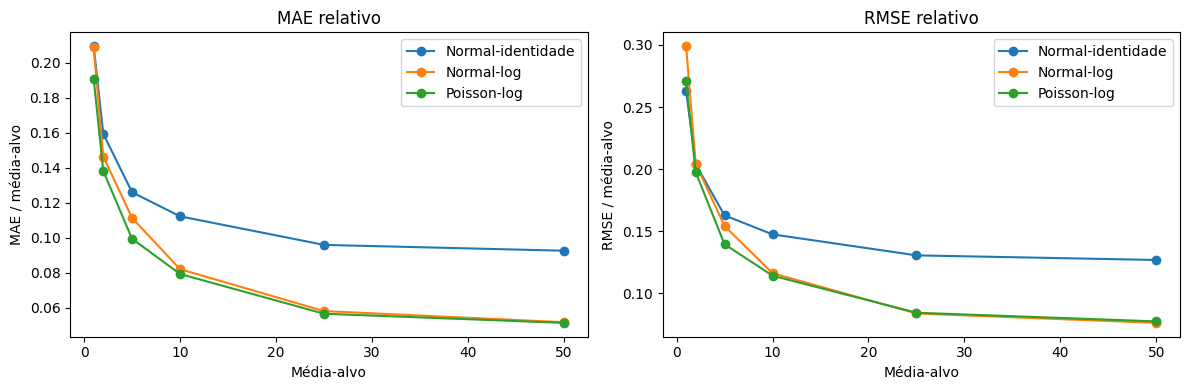

In [ ]:
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CÁLCULO DAS MÉTRICAS RELATIVAS
# ==============================================================================
comparacao_medias["mae_relativo"] = (
    comparacao_medias["mae_lambda"] / comparacao_medias["media_alvo"]
)

comparacao_medias["rmse_relativo"] = (
    comparacao_medias["rmse_lambda"] / comparacao_medias["media_alvo"]
)

comparacao_medias["vies_relativo"] = (
    comparacao_medias["vies"] / comparacao_medias["media_alvo"]
)

colunas_exibicao = [
    "media_alvo",
    "modelo",
    "mae_relativo",
    "rmse_relativo",
    "vies_relativo",
    "percentual_negativos",
    "dispersao_pearson",
]

display(
    comparacao_medias[colunas_exibicao].sort_values(["media_alvo", "modelo"])
)

# ==============================================================================
# 2. VISUALIZAÇÃO COMPARATIVA DOS MODELOS
# ==============================================================================
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

for nome_modelo, dados_modelo in comparacao_medias.groupby("modelo"):
    dados_modelo = dados_modelo.sort_values("media_alvo")

    eixos[0].plot(
        dados_modelo["media_alvo"],
        dados_modelo["mae_relativo"],
        marker="o",
        label=nome_modelo,
    )

    eixos[1].plot(
        dados_modelo["media_alvo"],
        dados_modelo["rmse_relativo"],
        marker="o",
        label=nome_modelo,
    )

eixos[0].set(
    xlabel="Média-alvo",
    ylabel="MAE / média-alvo",
    title="MAE relativo",
)

eixos[1].set(
    xlabel="Média-alvo",
    ylabel="RMSE / média-alvo",
    title="RMSE relativo",
)

eixos[0].legend()
eixos[1].legend()

plt.tight_layout()
plt.show()

Criando uma série de repetições para a simulação da Poisson com as diferentes médias.

In [ ]:
import numpy as np
import pandas as pd
import patsy
import statsmodels.api as sm

# 1. Matriz de preditores avaliada uma única vez
formula_preditora = (
    "1 + " + " + ".join(PREDITORES_PADRONIZADOS) + " + C(geo)" + " + C(time)"
)

X = patsy.dmatrix(
    formula_preditora,
    data=base_glm,
    return_type="dataframe",
)

print("Dimensão da matriz X:", X.shape)
print("Posto da matriz:     ", np.linalg.matrix_rank(X))


# 2. Função de extração de métricas por réplica
def metricas_monte_carlo(
    media_alvo,
    repeticao,
    modelo,
    lambda_verdadeiro,
    previsao,
    dispersao=np.nan,
    convergiu=True,
):
    erro = previsao - lambda_verdadeiro

    return {
        "media_alvo": media_alvo,
        "repeticao": repeticao,
        "modelo": modelo,
        "convergiu": convergiu,
        "media_prevista": previsao.mean(),
        "vies": erro.mean(),
        "mae": np.mean(np.abs(erro)),
        "rmse": np.sqrt(np.mean(erro**2)),
        "mae_relativo": np.mean(np.abs(erro)) / media_alvo,
        "rmse_relativo": np.sqrt(np.mean(erro**2)) / media_alvo,
        "correlacao": np.corrcoef(previsao, lambda_verdadeiro)[0, 1],
        "percentual_negativos": 100 * np.mean(previsao < 0),
        "dispersao_pearson": dispersao,
    }

Dimensão da matriz X: (3120, 181)
Posto da matriz:      181


Simulação

In [ ]:
from tqdm.auto import tqdm

NUM_REPLICACOES = 100
resultados_monte_carlo = []

total_execucoes = len(medias_alvo) * NUM_REPLICACOES
barra = tqdm(total=total_execucoes)

for media_alvo in medias_alvo:
    lambda_verdadeiro = lambdas[media_alvo].reshape(-1)

    for repeticao in range(NUM_REPLICACOES):
        semente = np.random.SeedSequence([20260915, media_alvo, repeticao])
        gerador = np.random.default_rng(semente)
        y_simulado = gerador.poisson(lambda_verdadeiro)

        # 1. Poisson com link log
        ajuste_poisson = sm.GLM(
            y_simulado,
            X,
            family=sm.families.Poisson(),
        ).fit(maxiter=200)

        pred_poisson = np.asarray(ajuste_poisson.predict(X))
        dispersao_poisson = (
            ajuste_poisson.pearson_chi2 / ajuste_poisson.df_resid
        )

        resultados_monte_carlo.append(
            metricas_monte_carlo(
                media_alvo=media_alvo,
                repeticao=repeticao,
                modelo="Poisson-log",
                lambda_verdadeiro=lambda_verdadeiro,
                previsao=pred_poisson,
                dispersao=dispersao_poisson,
                convergiu=ajuste_poisson.converged,
            )
        )

        # 2. Normal com link log
        ajuste_normal_log = sm.GLM(
            y_simulado,
            X,
            family=sm.families.Gaussian(link=sm.families.links.Log()),
        ).fit(maxiter=200)

        pred_normal_log = np.asarray(ajuste_normal_log.predict(X))

        resultados_monte_carlo.append(
            metricas_monte_carlo(
                media_alvo=media_alvo,
                repeticao=repeticao,
                modelo="Normal-log",
                lambda_verdadeiro=lambda_verdadeiro,
                previsao=pred_normal_log,
                convergiu=ajuste_normal_log.converged,
            )
        )

        # 3. Normal com link identidade
        ajuste_normal_id = sm.OLS(y_simulado, X).fit()
        pred_normal_id = np.asarray(ajuste_normal_id.predict(X))

        resultados_monte_carlo.append(
            metricas_monte_carlo(
                media_alvo=media_alvo,
                repeticao=repeticao,
                modelo="Normal-identidade",
                lambda_verdadeiro=lambda_verdadeiro,
                previsao=pred_normal_id,
            )
        )

        barra.update(1)

barra.close()

resultados_mc = pd.DataFrame(resultados_monte_carlo)
print("Quantidade de resultados gerados:", len(resultados_mc))
display(resultados_mc.head())

  0%|          | 0/600 [00:00<?, ?it/s]

Quantidade de resultados gerados: 1800


,media_alvo,repeticao,modelo,convergiu,media_prevista,vies,mae,rmse,mae_relativo,rmse_relativo,correlacao,percentual_negativos,dispersao_pearson
0,1,0,Poisson-log,True,0.972756,-0.027244,0.193596,0.272378,0.193596,0.272378,0.896861,0.000000,0.970227
1,1,0,Normal-log,True,0.968002,-0.031998,0.202661,0.284293,0.202661,0.284293,0.888200,0.000000,NaN
2,1,0,Normal-identidade,True,0.972756,-0.027244,0.209324,0.262097,0.209324,0.262097,0.897315,3.429487,NaN
3,1,1,Poisson-log,True,0.969551,-0.030449,0.200580,0.281476,0.200580,0.281476,0.896042,0.000000,1.019552
4,1,1,Normal-log,True,0.959971,-0.040029,0.227046,0.316145,0.227046,0.316145,0.876704,0.000000,NaN


Diagnósticos

In [ ]:
# 1. Diagnóstico de convergência computacional
display(
    resultados_mc.groupby(["media_alvo", "modelo"])["convergiu"].agg(
        ["count", "sum", "mean"]
    )
)

# 2. Agregação descritiva de Monte Carlo
resumo_mc = (
    resultados_mc.groupby(["media_alvo", "modelo"])
    .agg(
        mae_relativo_medio=("mae_relativo", "mean"),
        mae_relativo_dp=("mae_relativo", "std"),
        rmse_relativo_medio=("rmse_relativo", "mean"),
        rmse_relativo_dp=("rmse_relativo", "std"),
        correlacao_media=("correlacao", "mean"),
        negativos_medio=("percentual_negativos", "mean"),
        dispersao_media=("dispersao_pearson", "mean"),
    )
    .reset_index()
)
display(resumo_mc)

# 3. Comparação pareada: Poisson vs Normal-log
rmse_pareado = resultados_mc.pivot(
    index=["media_alvo", "repeticao"],
    columns="modelo",
    values="rmse_relativo",
).reset_index()

rmse_pareado["delta_normal_log_poisson"] = (
    rmse_pareado["Normal-log"] - rmse_pareado["Poisson-log"]
)


def quantil_025(serie):
    return serie.quantile(0.025)


def quantil_975(serie):
    return serie.quantile(0.975)


resumo_diferencas = (
    rmse_pareado.groupby("media_alvo")["delta_normal_log_poisson"]
    .agg(
        media="mean",
        mediana="median",
        desvio="std",
        limite_025=quantil_025,
        limite_975=quantil_975,
        proporcao_poisson_melhor=lambda x: (x > 0).mean(),
    )
    .reset_index()
)
display(resumo_diferencas)

count  sum  mean
media_alvo modelo                             
1          Normal-identidade    100  100   1.0
           Normal-log           100  100   1.0
           Poisson-log          100  100   1.0
2          Normal-identidade    100  100   1.0
           Normal-log           100  100   1.0
           Poisson-log          100  100   1.0
5          Normal-identidade    100  100   1.0
           Normal-log           100  100   1.0
           Poisson-log          100  100   1.0
10         Normal-identidade    100  100   1.0
           Normal-log           100  100   1.0
           Poisson-log          100  100   1.0
25         Normal-identidade    100  100   1.0
           Normal-log           100  100   1.0
           Poisson-log          100  100   1.0
50         Normal-identidade    100  100   1.0
           Normal-log           100  100   1.0
           Poisson-log          100  100   1.0

,media_alvo,modelo,mae_relativo_medio,mae_relativo_dp,rmse_relativo_medio,rmse_relativo_dp,correlacao_media,negativos_medio,dispersao_media
0,1,Normal-identidade,0.213862,0.010099,0.269357,0.012329,0.895736,3.223077,NaN
1,1,Normal-log,0.217395,0.011545,0.308834,0.017656,0.880333,0.000000,NaN
2,1,Poisson-log,0.197318,0.010875,0.279655,0.016321,0.896280,0.000000,1.000856
3,2,Normal-identidade,0.165662,0.006715,0.210048,0.008034,0.933012,2.389103,NaN
4,2,Normal-log,0.157102,0.007741,0.220331,0.011018,0.931388,0.000000,NaN
5,2,Poisson-log,0.144664,0.007319,0.204092,0.010865,0.940662,0.000000,1.010139
6,5,Normal-identidade,0.126047,0.003320,0.162873,0.003904,0.958293,1.783333,NaN
7,5,Normal-log,0.105117,0.004423,0.146701,0.006083,0.967229,0.000000,NaN
8,5,Poisson-log,0.097984,0.004294,0.138573,0.006157,0.971116,0.000000,1.020252
9,10,Normal-identidade,0.109486,0.002298,0.144018,0.002528,0.967182,1.670513,NaN


,media_alvo,media,mediana,desvio,limite_025,limite_975,proporcao_poisson_melhor
0,1,0.029179,0.028406,0.009528,0.012172,0.047761,1.00
1,2,0.016239,0.015962,0.006707,0.004389,0.029312,1.00
2,5,0.008129,0.008266,0.003683,0.000719,0.014105,1.00
3,10,0.003014,0.002956,0.002718,-0.001649,0.007975,0.86
4,25,-0.000166,-0.000029,0.001640,-0.003398,0.002822,0.50
5,50,-0.001650,-0.001686,0.001055,-0.003579,0.000404,0.07


Poisson parece ser importante para contagens mais baixas, para contagens altas a proporção de vezes que Poisson foi melhor reduz bem.

- Poisson apresetna valores melhores com média 1, 2 e 5;
- Em 10 a diferença para llog-normal diminui;
- Normal identidade apresenta valores negativos

# Testando parâmetros simulados


1. Extração dos Parâmetros do Meridian

A inferência do Meridian disponibiliza as distribuições a posteriori dos parâmetros através do objeto inference_data.posterior. Para construir o cenário de pseudoverdade (ground truth), extraem-se as variáveis latentes estimadas pelo modelo:

Parâmetros de saturação e memória: alpha_m (decaimento de adstock), ec_m (meia-vida de Hill) e slope_m (inclinação de Hill).

Efeitos de canal e controle: beta_gm (efeito de mídia específico por geo e canal) e gamma_gc (efeito de covariáveis de controle por geo).

Componentes de nível: mu_t (efeito temporal baseline) e tau_g (efeito fixo por geografia).Após verificar a ausência de parâmetros faltantes, calcula-se a média a posteriori de cada tensor marginalizando as cadeias e sorteios (chain e draw).

 As dimensões esperadas refletem a estrutura do painel:alpha: (4,) — 4 canais de mídiaec: (4,) — 4 canais de mídiaslope: (4,) — 4 canais de mídiabeta_gm: (20, 4) — 20 geos e 4 canaisgamma_gc: (20, 2) — 20 geos e 2 variáveis de controlemu_t: (156,) — 156 semanastau_g: (20,) — 20 geos

 2. Simplificação dos Efeitos Geográficos de Mídia.

 Nesta primeira etapa de validação, os coeficientes específicos por localidade são simplificados para a média nacional entre geografias. Em vez de atribuir valores arbitrários, calcula-se a média direta dos efeitos estimados:

 $$\beta_m^{\text{pseudo}} = \frac{1}{G} \sum_g \widehat\beta_{g,m}$$$$\gamma_c^{\text{pseudo}} = \frac{1}{G} \sum_g \widehat\gamma_{g,c}$$

 Essa consolidação gera uma tabela de referência (pseudoverdade) com os parâmetros definitivos de decaimento, saturação e coeficiente de impacto para cada canal.

 3. Aplicação das Transformações de Mídia (Adstock e Hill)

 O tensor media_scaled presente no contexto do modelo já incorpora as padronizações internas do Meridian (ajuste por população e escala pela mediana não nula).A transformação dos investimentos brutos em impacto publicitário efetivo ocorre aplicando as funções estruturais do modelo:

 Adstock: modela a retenção e o efeito acumulado da mídia ao longo do tempo via alpha_pseudo.

 Hill: modela os retornos decrescentes e a saturação da resposta via ec_pseudo e slope_pseudo.A chamada via equacoes.adstock_hill_media preserva a ordem de avaliação e a parametrização original da biblioteca. O tensor transformado resultante assume as dimensões (20, 156, 4).

 4. Obtenção das Covariáveis de ControleOs tensores de variáveis de controle escalonadas são extraídos diretamente de contexto.controls_scaled, mantendo a mesma matriz dimensional do painel: (20, 156, 2), correspondendo a 20 geos, 156 semanas e 2 covariáveis.

 5. Construção do Preditor Linear Pseudo-Verdadeiro

 O preditor linear $\eta_{g,t}$ consolida todas as forças modeladas sobre a variável dependente através de contrações de produto interno (via np.einsum):

 $$\eta_{g,t}^{\text{pseudo}} = \mu_t + \tau_g + \sum_m x_{g,t,m}^{\text{transf}} \beta_m^{\text{pseudo}} + \sum_c z_{g,t,c}^{\text{escalado}} \gamma_c^{\text{pseudo}}$$

 A matriz $\eta$ resultante possui dimensões (20, 156) e resume o valor do log-cenário base antes do vínculo exponencial da função de ligação.6. Calibração de Taxas ($\lambda$) com Múltiplas Médias GlobaisPara prevenir overflow numérico no cálculo da exponencial, subtrai-se o valor máximo de $\eta$ antes da transformação:

 $$\eta_{\text{estabilizado}} = \eta^{\text{pseudo}} - \max(\eta^{\text{pseudo}})$$A forma relativa da curva é obtida normalizando o risco relativo pela sua média empírica:$$\text{forma\_relativa}_{g,t} = \frac{\exp(\eta_{g,t}^{\text{estabilizado}})}{\overline{\exp(\eta^{\text{estabilizado}})}}$$

 Ao multiplicar essa curva base por médias alvo $L \in \{1, 2, 5, 10, 25, 50\}$, preserva-se estritamente a inclinação marginal de cada canal:

 $$\log\lambda_{g,t}^{(L)} = \underbrace{\log L - \log\overline{\exp(\eta)}}_{\text{novo intercepto}} + \eta_{g,t}$$

 Como a alteração da média atua exclusivamente como uma translação no intercepto global do modelo linear generalizado, os coeficientes de elasticidade originais permanecem invariantes:

 $$\beta_m^{\text{pseudo}}, \qquad \gamma_j^{\text{pseudo}}$$

 Esse desenho experimental permite gerar respostas sintéticas de Poisson ou Log-Normal sob diferentes regimes de volume e avaliar a taxa de convergência dos estimadores:

 $$\widehat\beta_m \quad\text{contra}\quad \beta_m^{\text{pseudo}}$$

In [ ]:
# ==============================================================================
# 1. EXTRAÇÃO DOS PARÂMETROS POSTERIORES DO MERIDIAN (PSEUDO-VERDADE)
# ==============================================================================
import numpy as np
import pandas as pd
from meridian.model import equations

posterior = modelo_meridian.inference_data.posterior

# Variáveis necessárias para construir o preditor linear
variaveis_necessarias = [
    "alpha_m", "ec_m", "slope_m", "beta_gm", "gamma_gc", "mu_t", "tau_g"
]

variaveis_ausentes = [v for v in variaveis_necessarias if v not in posterior]
print("Variáveis ausentes na posterior:", variaveis_ausentes)

# Função para extrair a média posterior (médias das cadeias e draws)
def media_posterior(nome):
    return posterior[nome].mean(dim=["chain", "draw"]).values

alpha_pseudo = media_posterior("alpha_m")
ec_pseudo = media_posterior("ec_m")
slope_pseudo = media_posterior("slope_m")
beta_gm_pseudo = media_posterior("beta_gm")
gamma_gc_pseudo = media_posterior("gamma_gc")
mu_t_pseudo = media_posterior("mu_t")
tau_g_pseudo = media_posterior("tau_g")

# Verificação das dimensões extraídas
print("Dimensões dos parâmetros extraídos:")
print(f"  alpha_m (canais):              {alpha_pseudo.shape}")
print(f"  ec_m (canais):                 {ec_pseudo.shape}")
print(f"  slope_m (canais):              {slope_pseudo.shape}")
print(f"  beta_gm (geos x canais):       {beta_gm_pseudo.shape}")
print(f"  gamma_gc (geos x controles):   {gamma_gc_pseudo.shape}")
print(f"  mu_t (tempo/semanas):          {mu_t_pseudo.shape}")
print(f"  tau_g (geos):                  {tau_g_pseudo.shape}")

# ==============================================================================
# 2. SIMPLIFICAÇÃO DOS EFEITOS GEOGRÁFICOS DE MÍDIA E CONTROLES
# ==============================================================================
# Para o primeiro experimento, simplificamos os parâmetros tomando a média entre geos
beta_m_pseudo = beta_gm_pseudo.mean(axis=0)
gamma_c_pseudo = gamma_gc_pseudo.mean(axis=0)

tabela_pseudoverdade = pd.DataFrame({
    "canal": NOMES_CANAIS,
    "alpha_pseudo": alpha_pseudo,
    "ec_pseudo": ec_pseudo,
    "slope_pseudo": slope_pseudo,
    "beta_pseudo": beta_m_pseudo
})

print("\nTabela de Parâmetros Pseudo-Verdadeiros de Mídia:")
display(tabela_pseudoverdade)

# ==============================================================================
# 3. TRANSFORMAÇÃO DE MÍDIA VIA EQUAÇÕES INTERNAS DO MERIDIAN
# ==============================================================================
contexto = modelo_meridian.model_context
equacoes = equations.ModelEquations(contexto)

# Coleta da mídia escalada (já padronizada pelo Meridian)
midia_escalada = contexto.media_tensors.media_scaled

# Aplicação simultânea de Adstock e Hill na parametrização do Meridian
midia_transformada = equacoes.adstock_hill_media(
    media=midia_escalada,
    alpha=alpha_pseudo,
    ec=ec_pseudo,
    slope=slope_pseudo,
    decay_functions=contexto.adstock_decay_spec.media,
    saturation_spec=contexto.saturation_spec.media
)
midia_transformada = np.asarray(midia_transformada)
print(f"\nFormato final da mídia transformada (G x T x M): {midia_transformada.shape}")

# ==============================================================================
# 4. RECUPERAÇÃO DOS CONTROLES ESCALADOS
# ==============================================================================
controles_escalados = np.asarray(contexto.controls_scaled)
print(f"Formato dos controles escalados (G x T x C): {controles_escalados.shape}")

# ==============================================================================
# 5. CONSTRUÇÃO DO PREDITOR LINEAR PSEUDO-VERDADEIRO (ETA)
# ==============================================================================
efeito_midia = np.einsum("gtm,m->gt", midia_transformada, beta_m_pseudo)
efeito_controles = np.einsum("gtc,c->gt", controles_escalados, gamma_c_pseudo)

# Combinação de todos os efeitos e termos de intercepto (tempo + geo)
eta_pseudo = (
    mu_t_pseudo[None, :] +
    tau_g_pseudo[:, None] +
    efeito_midia +
    efeito_controles
)

print(f"\nDiagnóstico do Preditor Linear (eta_pseudo):")
print(f"  Formato: {eta_pseudo.shape}")
print(f"  Mínimo:  {eta_pseudo.min():.6f}")
print(f"  Média:   {eta_pseudo.mean():.6f}")
print(f"  Máximo:  {eta_pseudo.max():.6f}")

# ==============================================================================
# 6. GERAÇÃO DOS VALORES DE LAMBDA ADAPTADOS PARA MÚLTIPLAS MÉDIAS GLOBAIS
# ==============================================================================
# Subtração do máximo para estabilização exponencial numérica
eta_estabilizado = eta_pseudo - eta_pseudo.max()
risco_relativo_pseudo = np.exp(eta_estabilizado)
forma_relativa_pseudo = risco_relativo_pseudo / risco_relativo_pseudo.mean()

medias_alvo = [1, 2, 5, 10, 25, 50]
lambdas_pseudo = {
    media_alvo: (media_alvo * forma_relativa_pseudo) for media_alvo in medias_alvo
}

print("\nValidação das médias e limites de lambda simulados:")
for media_alvo in medias_alvo:
    valores = lambdas_pseudo[media_alvo]
    print(f"  Alvo {media_alvo:2d} -> Média: {valores.mean():7.4f} | Mín: {valores.min():7.4f} | Máx: {valores.max():7.4f}")

Variáveis ausentes na posterior: []
Dimensões dos parâmetros extraídos:
  alpha_m (canais):              (4,)
  ec_m (canais):                 (4,)
  slope_m (canais):              (4,)
  beta_gm (geos x canais):       (20, 4)
  gamma_gc (geos x controles):   (20, 2)
  mu_t (tempo/semanas):          (156,)
  tau_g (geos):                  (20,)

Tabela de Parâmetros Pseudo-Verdadeiros de Mídia:


,canal,alpha_pseudo,ec_pseudo,slope_pseudo,beta_pseudo
0,Channel0,0.393461,1.542406,1.0,0.563117
1,Channel1,0.274464,1.696851,1.0,0.393939
2,Channel2,0.454781,0.749062,1.0,0.544910
3,Channel3,0.226652,1.147394,1.0,0.482688



Formato final da mídia transformada (G x T x M): (20, 156, 4)
Formato dos controles escalados (G x T x C): (20, 156, 2)

Diagnóstico do Preditor Linear (eta_pseudo):
  Formato: (20, 156)
  Mínimo:  -3.775569
  Média:   -0.018367
  Máximo:  3.233844

Validação das médias e limites de lambda simulados:
  Alvo  1 -> Média:  1.0000 | Mín:  0.0146 | Máx: 16.1127
  Alvo  2 -> Média:  2.0000 | Mín:  0.0291 | Máx: 32.2253
  Alvo  5 -> Média:  5.0000 | Mín:  0.0728 | Máx: 80.5633
  Alvo 10 -> Média: 10.0000 | Mín:  0.1456 | Máx: 161.1266
  Alvo 25 -> Média: 25.0000 | Mín:  0.3639 | Máx: 402.8164
  Alvo 50 -> Média: 50.0000 | Mín:  0.7278 | Máx: 805.6328


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ---------------------------------------------------------
# 2. Criar a tabela do novo DGP
# ---------------------------------------------------------

base_recuperacao = pd.MultiIndex.from_product(
    [geos, tempos], names=["geo", "time"]
).to_frame(index=False)

colunas_midia_dgp = []
for indice, canal in enumerate(NOMES_CANAIS):
    coluna = f"hill_adstock_{canal}"
    base_recuperacao[coluna] = midia_transformada[:, :, indice].reshape(-1)
    colunas_midia_dgp.append(coluna)

nomes_controles_dgp = []
for indice, controle in enumerate(COLUNAS_CONTROLE):
    coluna = f"controle_escalado_{indice}"
    base_recuperacao[coluna] = controles_escalados[:, :, indice].reshape(-1)
    nomes_controles_dgp.append(coluna)

# ---------------------------------------------------------
# 3. Simular uma primeira amostra (Média-alvo = 2)
# ---------------------------------------------------------

MEDIA_TESTE = 2
SEMENTE_TESTE = 123

lambda_teste = lambdas_pseudo[MEDIA_TESTE].reshape(-1)
gerador = np.random.default_rng(SEMENTE_TESTE)

base_recuperacao["lambda_verdadeiro"] = lambda_teste
base_recuperacao["y_contagem"] = gerador.poisson(lambda_teste)

print(base_recuperacao[["lambda_verdadeiro", "y_contagem"]].describe())

# ---------------------------------------------------------
# 4. Definir a mesma função média nos dois modelos
# ---------------------------------------------------------

termos_covariaveis = " + ".join(colunas_midia_dgp + nomes_controles_dgp)
formula_recuperacao = f"y_contagem ~ {termos_covariaveis} + C(geo) + C(time)"

print(formula_recuperacao)

# ---------------------------------------------------------
# 5. Ajustar Poisson-log
# ---------------------------------------------------------

modelo_pseudo_poisson = smf.glm(
    formula=formula_recuperacao,
    data=base_recuperacao,
    family=sm.families.Poisson(),
).fit(maxiter=200)

print("Poisson convergiu:", modelo_pseudo_poisson.converged)

# ---------------------------------------------------------
# 6. Ajustar Normal-log
# ---------------------------------------------------------

modelo_pseudo_normal_log = smf.glm(
    formula=formula_recuperacao,
    data=base_recuperacao,
    family=sm.families.Gaussian(link=sm.families.links.Log()),
).fit(maxiter=200)

print("Normal-log convergiu:", modelo_pseudo_normal_log.converged)

# ---------------------------------------------------------
# 7. Comparar os betas estimados
# ---------------------------------------------------------

tabela_recuperacao_beta = pd.DataFrame(
    {
        "canal": NOMES_CANAIS,
        "beta_pseudo_verdadeiro": beta_m_pseudo,
        "beta_poisson": [
            modelo_pseudo_poisson.params[coluna] for coluna in colunas_midia_dgp
        ],
        "beta_normal_log": [
            modelo_pseudo_normal_log.params[coluna] for coluna in colunas_midia_dgp
        ],
    }
)

# Cálculo dos erros de recuperação
tabela_recuperacao_beta["erro_poisson"] = (
    tabela_recuperacao_beta["beta_poisson"]
    - tabela_recuperacao_beta["beta_pseudo_verdadeiro"]
)

tabela_recuperacao_beta["erro_normal_log"] = (
    tabela_recuperacao_beta["beta_normal_log"]
    - tabela_recuperacao_beta["beta_pseudo_verdadeiro"]
)

display(tabela_recuperacao_beta)

       lambda_verdadeiro   y_contagem
count        3120.000000  3120.000000
mean            2.000000     1.969551
std             2.428347     2.755979
min             0.029110     0.000000
25%             0.646840     0.000000
50%             1.259939     1.000000
75%             2.428521     3.000000
max            32.225312    33.000000
y_contagem ~ hill_adstock_Channel0 + hill_adstock_Channel1 + hill_adstock_Channel2 + hill_adstock_Channel3 + controle_escalado_0 + controle_escalado_1 + C(geo) + C(time)
Poisson convergiu: True
Normal-log convergiu: True


,canal,beta_pseudo_verdadeiro,beta_poisson,beta_normal_log,erro_poisson,erro_normal_log
0,Channel0,0.563117,0.514317,0.655958,-0.048799,0.092842
1,Channel1,0.393939,0.164682,0.173921,-0.229256,-0.220017
2,Channel2,0.544910,0.787576,1.074181,0.242665,0.529270
3,Channel3,0.482688,0.363196,0.372895,-0.119492,-0.109793


Avaliando intervalos de confiança para os betas

In [ ]:
import pandas as pd


# -------------------------------------------------------------------------
# 1. Função para avaliar a cobertura dos intervalos de confiança
# -------------------------------------------------------------------------
def tabela_intervalos_beta(modelo, nome_modelo):
    """Calcula os intervalos de confiança dos betas e verifica se contêm o valor pseudo-verdadeiro."""
    intervalos = modelo.conf_int()
    linhas = []

    for indice, coluna in enumerate(colunas_midia_dgp):
        beta_verdadeiro = beta_m_pseudo[indice]
        estimativa = modelo.params[coluna]
        erro_padrao = modelo.bse[coluna]
        limite_inferior = intervalos.loc[coluna, 0]
        limite_superior = intervalos.loc[coluna, 1]

        linhas.append({
            "modelo": nome_modelo,
            "canal": NOMES_CANAIS[indice],
            "beta_verdadeiro": beta_verdadeiro,
            "beta_estimado": estimativa,
            "erro": estimativa - beta_verdadeiro,
            "erro_padrao": erro_padrao,
            "limite_inferior": limite_inferior,
            "limite_superior": limite_superior,
            "cobriu_verdadeiro": (
                limite_inferior <= beta_verdadeiro <= limite_superior
            ),
        })

    return pd.DataFrame(linhas)


# -------------------------------------------------------------------------
# 2. Avaliação dos intervalos para Poisson-log e Normal-log
# -------------------------------------------------------------------------
intervalos_poisson = tabela_intervalos_beta(
    modelo_pseudo_poisson, "Poisson-log"
)
intervalos_normal_log = tabela_intervalos_beta(
    modelo_pseudo_normal_log, "Normal-log"
)

comparacao_intervalos = pd.concat(
    [intervalos_poisson, intervalos_normal_log],
    ignore_index=True,
)

display(comparacao_intervalos)

# Resumo da taxa de cobertura (inspeção da realização individual)
cobertura_resumo = comparacao_intervalos.groupby("modelo")[
    "cobriu_verdadeiro"
].agg(["sum", "count", "mean"])

display(cobertura_resumo)


,modelo,canal,beta_verdadeiro,beta_estimado,erro,erro_padrao,limite_inferior,limite_superior,cobriu_verdadeiro
0,Poisson-log,Channel0,0.563117,0.514317,-0.048799,0.236108,0.051554,0.977081,True
1,Poisson-log,Channel1,0.393939,0.164682,-0.229256,0.237812,-0.301421,0.630786,True
2,Poisson-log,Channel2,0.544910,0.787576,0.242665,0.245598,0.306213,1.268938,True
3,Poisson-log,Channel3,0.482688,0.363196,-0.119492,0.249616,-0.126043,0.852435,True
4,Normal-log,Channel0,0.563117,0.655958,0.092842,0.163399,0.335702,0.976215,True
5,Normal-log,Channel1,0.393939,0.173921,-0.220017,0.181320,-0.181459,0.529301,True
6,Normal-log,Channel2,0.544910,1.074181,0.529270,0.181889,0.717684,1.430677,False
7,Normal-log,Channel3,0.482688,0.372895,-0.109793,0.177995,0.024030,0.721760,True


,sum,count,mean
modelo,,,
Normal-log,3,4,0.75
Poisson-log,4,4,1.00


Simulação de Monte Carlo

1. Matriz de preditores fixa

In [ ]:
import patsy
import statsmodels.api as sm
from tqdm.auto import tqdm

formula_x_recuperacao = (
    "1 + "
    + " + ".join(colunas_midia_dgp + nomes_controles_dgp)
    + " + C(geo) + C(time)"
)

X_recuperacao = patsy.dmatrix(
    formula_x_recuperacao,
    data=base_recuperacao,
    return_type="dataframe",
)

print("Dimensão de X:", X_recuperacao.shape)

Dimensão de X: (3120, 181)


Configuração

In [ ]:
NUM_REPLICACOES = 100

resultados_beta = []
resultados_predicao = []

Função para acumular os betas

In [ ]:
def registrar_betas(ajuste, modelo, media_alvo, repeticao):
    intervalos = ajuste.conf_int(alpha=0.05)

    for indice, coluna in enumerate(colunas_midia_dgp):
        beta_verdadeiro = beta_m_pseudo[indice]
        beta_estimado = ajuste.params[coluna]
        erro_padrao = ajuste.bse[coluna]
        limite_inferior = intervalos.loc[coluna, 0]
        limite_superior = intervalos.loc[coluna, 1]

        resultados_beta.append({
            "media_alvo": media_alvo,
            "repeticao": repeticao,
            "modelo": modelo,
            "canal": NOMES_CANAIS[indice],
            "beta_verdadeiro": beta_verdadeiro,
            "beta_estimado": beta_estimado,
            "erro": beta_estimado - beta_verdadeiro,
            "erro_quadratico": (beta_estimado - beta_verdadeiro) ** 2,
            "erro_padrao": erro_padrao,
            "limite_inferior": limite_inferior,
            "limite_superior": limite_superior,
            "largura_intervalo": limite_superior - limite_inferior,
            "cobriu": limite_inferior <= beta_verdadeiro <= limite_superior,
        })

Função para gravar a recuperação de $\lambda$

In [ ]:
def registrar_predicao(
    modelo,
    media_alvo,
    repeticao,
    lambda_verdadeiro,
    previsao,
    dispersao=np.nan,
):
    erro = previsao - lambda_verdadeiro

    resultados_predicao.append({
        "media_alvo": media_alvo,
        "repeticao": repeticao,
        "modelo": modelo,
        "vies_lambda": erro.mean(),
        "mae_lambda": np.mean(np.abs(erro)),
        "rmse_lambda": np.sqrt(np.mean(erro**2)),
        "mae_relativo": np.mean(np.abs(erro)) / media_alvo,
        "rmse_relativo": np.sqrt(np.mean(erro**2)) / media_alvo,
        "correlacao_lambda": np.corrcoef(previsao, lambda_verdadeiro)[0, 1],
        "dispersao_pearson": dispersao,
    })

Simulação

In [ ]:
total = len(medias_alvo) * NUM_REPLICACOES
barra = tqdm(total=total)

for media_alvo in medias_alvo:
    lambda_verdadeiro = lambdas_pseudo[media_alvo].reshape(-1)

    for repeticao in range(NUM_REPLICACOES):
        semente = np.random.SeedSequence([20260924, media_alvo, repeticao])
        gerador = np.random.default_rng(semente)
        y_simulado = gerador.poisson(lambda_verdadeiro)

        # Ajuste Poisson-log
        ajuste_poisson = sm.GLM(
            y_simulado,
            X_recuperacao,
            family=sm.families.Poisson(),
        ).fit(maxiter=200)

        pred_poisson = np.asarray(ajuste_poisson.predict(X_recuperacao))
        dispersao_poisson = (
            ajuste_poisson.pearson_chi2 / ajuste_poisson.df_resid
        )

        registrar_betas(
            ajuste=ajuste_poisson,
            modelo="Poisson-log",
            media_alvo=media_alvo,
            repeticao=repeticao,
        )

        registrar_predicao(
            modelo="Poisson-log",
            media_alvo=media_alvo,
            repeticao=repeticao,
            lambda_verdadeiro=lambda_verdadeiro,
            previsao=pred_poisson,
            dispersao=dispersao_poisson,
        )

        # Ajuste Normal-log
        ajuste_normal = sm.GLM(
            y_simulado,
            X_recuperacao,
            family=sm.families.Gaussian(link=sm.families.links.Log()),
        ).fit(maxiter=200)

        pred_normal = np.asarray(ajuste_normal.predict(X_recuperacao))

        registrar_betas(
            ajuste=ajuste_normal,
            modelo="Normal-log",
            media_alvo=media_alvo,
            repeticao=repeticao,
        )

        registrar_predicao(
            modelo="Normal-log",
            media_alvo=media_alvo,
            repeticao=repeticao,
            lambda_verdadeiro=lambda_verdadeiro,
            previsao=pred_normal,
        )

        barra.update(1)

barra.close()

  0%|          | 0/600 [00:00<?, ?it/s]

Resultados em DataFrame

In [ ]:
resultados_beta_mc = pd.DataFrame(resultados_beta)
resultados_predicao_mc = pd.DataFrame(resultados_predicao)

print("Linhas de betas:", resultados_beta_mc.shape)  # Esperado: 4.800
print("Linhas de predição:", resultados_predicao_mc.shape)  # Esperado: 1.200

Linhas de betas: (4800, 13)
Linhas de predição: (1200, 10)


Resumo os betas por canal

In [ ]:
resumo_beta_mc = (
    resultados_beta_mc.groupby(["media_alvo", "modelo", "canal"])
    .agg(
        beta_verdadeiro=("beta_verdadeiro", "first"),
        beta_estimado_medio=("beta_estimado", "mean"),
        vies=("erro", "mean"),
        erro_quadratico_medio=("erro_quadratico", "mean"),
        cobertura=("cobriu", "mean"),
        largura_media_intervalo=("largura_intervalo", "mean"),
        erro_padrao_medio=("erro_padrao", "mean"),
    )
    .reset_index()
)

resumo_beta_mc["rmse_beta"] = np.sqrt(
    resumo_beta_mc["erro_quadratico_medio"]
)

display(resumo_beta_mc)

,media_alvo,modelo,canal,beta_verdadeiro,beta_estimado_medio,vies,erro_quadratico_medio,cobertura,largura_media_intervalo,erro_padrao_medio,rmse_beta
0,1,Normal-log,Channel0,0.563117,0.628913,0.065796,0.215249,0.71,0.898384,0.229184,0.463949
1,1,Normal-log,Channel1,0.393939,0.363330,-0.030608,0.239286,0.72,0.989885,0.252526,0.489169
2,1,Normal-log,Channel2,0.544910,0.513698,-0.031212,0.216548,0.69,0.972627,0.248124,0.465348
3,1,Normal-log,Channel3,0.482688,0.569031,0.086343,0.267680,0.65,0.960201,0.244954,0.517378
4,1,Poisson-log,Channel0,0.563117,0.580547,0.017430,0.097673,0.96,1.306670,0.333340,0.312526
5,1,Poisson-log,Channel1,0.393939,0.334156,-0.059783,0.137344,0.94,1.315640,0.335629,0.370600
6,1,Poisson-log,Channel2,0.544910,0.527119,-0.017791,0.130086,0.94,1.345244,0.343181,0.360675
7,1,Poisson-log,Channel3,0.482688,0.505396,0.022707,0.129954,0.97,1.376963,0.351272,0.360491
8,2,Normal-log,Channel0,0.563117,0.554128,-0.008989,0.111216,0.76,0.638144,0.162795,0.333490
9,2,Normal-log,Channel1,0.393939,0.369562,-0.024377,0.086630,0.82,0.706039,0.180115,0.294329


REsumo agregado por modelo e salvando o csv

In [ ]:
# Resumo sobre os vieses médios
resumo_geral_beta = (
    resumo_beta_mc.groupby(["media_alvo", "modelo"])
    .agg(
        mae_beta=("vies", lambda x: np.mean(np.abs(x))),
        rmse_beta_medio=("rmse_beta", "mean"),
        cobertura_media=("cobertura", "mean"),
        largura_media=("largura_media_intervalo", "mean"),
    )
    .reset_index()
)

display(resumo_geral_beta)

# Resumo sobre o total de estimativas individuais (MAE e RMSE micro)
resumo_estimativas_beta = (
    resultados_beta_mc.assign(erro_absoluto=lambda d: np.abs(d["erro"]))
    .groupby(["media_alvo", "modelo"])
    .agg(
        mae_beta=("erro_absoluto", "mean"),
        rmse_beta=("erro_quadratico", lambda x: np.sqrt(x.mean())),
        cobertura=("cobriu", "mean"),
        largura_intervalo=("largura_intervalo", "mean"),
    )
    .reset_index()
)

display(resumo_estimativas_beta)

resultados_beta_mc.to_csv(
    "monte_carlo_recuperacao_betas.csv",
    index=False,
)

resultados_predicao_mc.to_csv(
    "monte_carlo_recuperacao_lambda.csv",
    index=False,
)

,media_alvo,modelo,mae_beta,rmse_beta_medio,cobertura_media,largura_media
0,1,Normal-log,0.053490,0.483961,0.6925,0.955274
1,1,Poisson-log,0.029428,0.351073,0.9525,1.336129
2,2,Normal-log,0.015883,0.327439,0.7250,0.679941
3,2,Poisson-log,0.012311,0.245863,0.9450,0.945620
4,5,Normal-log,0.011803,0.189701,0.7525,0.433064
5,5,Poisson-log,0.006998,0.150113,0.9550,0.597008
6,10,Normal-log,0.008012,0.128304,0.7900,0.305427
7,10,Poisson-log,0.009500,0.105496,0.9450,0.422414
8,25,Normal-log,0.005864,0.093168,0.7000,0.194599
9,25,Poisson-log,0.004582,0.070816,0.9475,0.267112


,media_alvo,modelo,mae_beta,rmse_beta,cobertura,largura_intervalo
0,1,Normal-log,0.385419,0.484449,0.6925,0.955274
1,1,Poisson-log,0.286353,0.351802,0.9525,1.336129
2,2,Normal-log,0.259339,0.328055,0.7250,0.679941
3,2,Poisson-log,0.198542,0.247584,0.9450,0.945620
4,5,Normal-log,0.155091,0.190241,0.7525,0.433064
5,5,Poisson-log,0.118554,0.150308,0.9550,0.597008
6,10,Normal-log,0.101648,0.128486,0.7900,0.305427
7,10,Poisson-log,0.084241,0.105809,0.9450,0.422414
8,25,Normal-log,0.073642,0.093253,0.7000,0.194599
9,25,Poisson-log,0.055432,0.070876,0.9475,0.267112


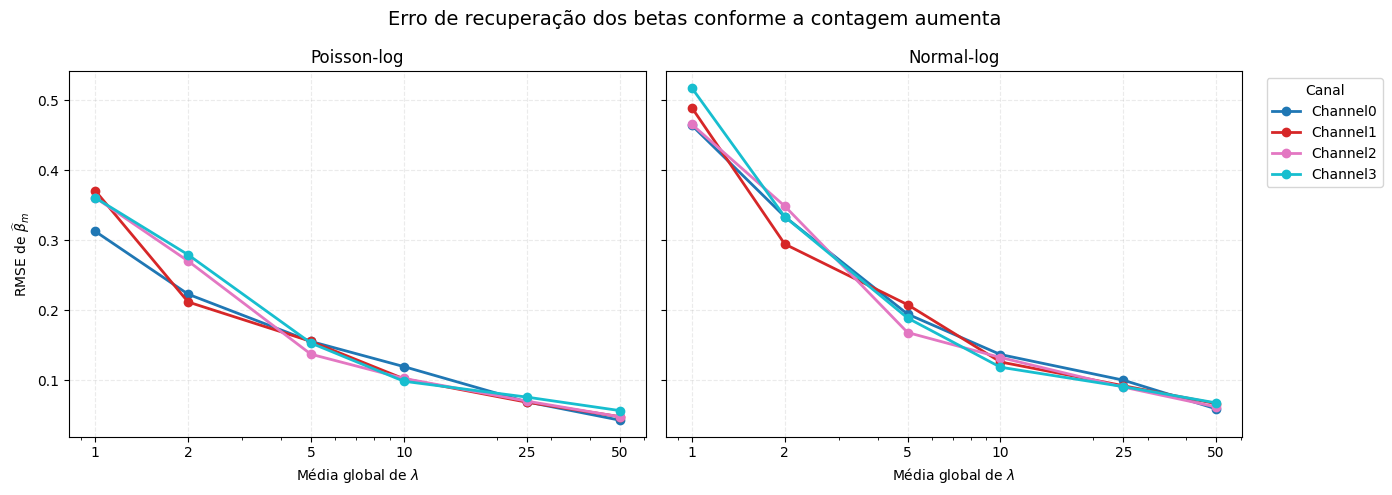

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ordem_canais = NOMES_CANAIS
ordem_medias = sorted(resumo_beta_mc["media_alvo"].unique())
ordem_modelos = ["Poisson-log", "Normal-log"]

cores = plt.cm.viridis(np.linspace(0.05, 0.95, len(ordem_medias)))
# -------------------------------------------------------------------------
# Gráfico: Erro de recuperação dos betas por modelo e canal
# -------------------------------------------------------------------------
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

cores_canais = plt.cm.tab10(np.linspace(0, 1, len(ordem_canais)))

for eixo, modelo in zip(eixos, ordem_modelos):
    dados_modelo = resumo_beta_mc.loc[resumo_beta_mc["modelo"] == modelo]

    for canal, cor in zip(ordem_canais, cores_canais):
        dados_canal = dados_modelo.loc[
            dados_modelo["canal"] == canal
        ].sort_values("media_alvo")

        eixo.plot(
            dados_canal["media_alvo"],
            dados_canal["rmse_beta"],
            marker="o",
            linewidth=2,
            color=cor,
            label=canal,
        )

    eixo.set_xscale("log")
    eixo.set_xticks(ordem_medias)
    eixo.set_xticklabels(ordem_medias)
    eixo.set_title(modelo)
    eixo.set_xlabel(r"Média global de $\lambda$")
    eixo.grid(alpha=0.25, linestyle="--")

eixos[0].set_ylabel(r"RMSE de $\widehat{\beta}_m$")
eixos[1].legend(title="Canal", bbox_to_anchor=(1.03, 1), loc="upper left")

fig.suptitle(
    "Erro de recuperação dos betas conforme a contagem aumenta",
    fontsize=14,
)

plt.tight_layout()
plt.show()

Avaliação da convergência dos parâmetros de saturação e esquecimento ( Hill e AdStock)


In [ ]:
# Inspeção dos hiperparâmetros e especificações estruturais
print("Max lag:", modelo_meridian.model_spec.max_lag)
print(
    "Hill antes do Adstock:",
    modelo_meridian.model_spec.hill_before_adstock,
)
print(
    "Decay:",
    modelo_meridian.model_context.adstock_decay_spec.media,
)
print(
    "Saturação:",
    modelo_meridian.model_context.saturation_spec.media,
)

Max lag: 8
Hill antes do Adstock: False
Decay: geometric
Saturação: hill


Comparação entre Priori e Posteriori


In [ ]:
import numpy as np
import pandas as pd


def resumir_prior_posterior(modelo, variavel):
    """Extrai estatísticas descritivas (média, desvio e quantis) para prior e posterior."""
    linhas = []

    for distribuicao in ["prior", "posterior"]:
        dados = getattr(modelo.inference_data, distribuicao)[variavel]
        nomes_canais = dados.coords["media_channel"].values

        for indice, canal in enumerate(nomes_canais):
            valores = (
                dados.isel(media_channel=indice).values.reshape(-1)
            )

            linhas.append({
                "parametro": variavel,
                "distribuicao": distribuicao,
                "canal": canal,
                "media": np.mean(valores),
                "desvio": np.std(valores),
                "q05": np.quantile(valores, 0.05),
                "mediana": np.quantile(valores, 0.50),
                "q95": np.quantile(valores, 0.95),
            })

    return pd.DataFrame(linhas)

    # Comparação de prior e posterior para decaimento (alpha) e meia-vida (ec)
resumo_alpha = resumir_prior_posterior(modelo_meridian, "alpha_m")
resumo_ec = resumir_prior_posterior(modelo_meridian, "ec_m")

resumo_transformacoes = pd.concat(
    [resumo_alpha, resumo_ec],
    ignore_index=True,
)

display(resumo_transformacoes)

,parametro,distribuicao,canal,media,desvio,q05,mediana,q95
0,alpha_m,prior,Channel0,0.511857,0.287074,0.080657,0.507580,0.954957
1,alpha_m,prior,Channel1,0.503041,0.298985,0.051791,0.511439,0.956331
2,alpha_m,prior,Channel2,0.462996,0.281691,0.036093,0.443644,0.938801
3,alpha_m,prior,Channel3,0.503685,0.288566,0.055363,0.492228,0.949194
4,alpha_m,posterior,Channel0,0.393461,0.039835,0.325750,0.393926,0.458641
5,alpha_m,posterior,Channel1,0.274464,0.057856,0.177488,0.273793,0.369275
6,alpha_m,posterior,Channel2,0.454781,0.044397,0.381320,0.455234,0.526931
7,alpha_m,posterior,Channel3,0.226652,0.055776,0.131706,0.227564,0.317354
8,ec_m,prior,Channel0,1.107358,0.632459,0.201101,1.075993,2.285683
9,ec_m,prior,Channel1,1.016823,0.582682,0.204479,0.964778,2.115190


Calculo Meia-vida

In [ ]:
# Para decaimento geométrico: meia_vida = log(0.5) / log(alpha)
alpha_draws = modelo_meridian.inference_data.posterior["alpha_m"]
alpha_seguro = np.clip(alpha_draws.values, 1e-8, 1 - 1e-8)
meia_vida_draws = np.log(0.5) / np.log(alpha_seguro)

resumo_meia_vida = []
for indice, canal in enumerate(NOMES_CANAIS):
    valores = meia_vida_draws[:, :, indice].reshape(-1)

    resumo_meia_vida.append({
        "canal": canal,
        "media": valores.mean(),
        "mediana": np.median(valores),
        "q05": np.quantile(valores, 0.05),
        "q95": np.quantile(valores, 0.95),
    })

resumo_meia_vida = pd.DataFrame(resumo_meia_vida)
display(resumo_meia_vida)

,canal,media,mediana,q05,q95
0,Channel0,0.747818,0.744046,0.617984,0.889234
1,Channel1,0.541190,0.535091,0.400929,0.695781
2,Channel2,0.887999,0.880809,0.718946,1.081884
3,Channel3,0.470194,0.468240,0.341926,0.603924


Curvas de Saturação

In [ ]:
from meridian.analysis import analyzer

# Inicialização do analisador oficial do Meridian
analisador_curvas = analyzer.Analyzer(
    model_context=modelo_meridian.model_context,
    inference_data=modelo_meridian.inference_data,
)

# Curvas de decaimento acumulado de Adstock
dados_adstock = analisador_curvas.adstock_decay(confidence_level=0.90)
display(dados_adstock.head(20))

# Curvas de resposta e saturação de Hill
dados_hill = analisador_curvas.hill_curves(
    confidence_level=0.90,
    n_bins=25,
)
display(dados_hill.head(20))

metric,channel,time_units,distribution,ci_hi,ci_lo,mean,is_int_time_unit
0,Channel0,0.0,posterior,1.000000,1.000000,1.000000,True
1,Channel0,0.0,prior,1.000000,1.000000,1.000000,True
2,Channel0,0.2,posterior,0.855647,0.799055,0.829122,False
3,Channel0,0.2,prior,0.990825,0.604382,0.841063,False
4,Channel0,0.4,posterior,0.732132,0.638489,0.687732,False
5,Channel0,0.4,prior,0.981733,0.365284,0.724857,False
6,Channel0,0.6,posterior,0.626446,0.510188,0.570691,False
7,Channel0,0.6,prior,0.972726,0.220780,0.636572,False
8,Channel0,0.8,posterior,0.536017,0.407669,0.473764,False
9,Channel0,0.8,prior,0.963800,0.133443,0.567411,False


,channel,media_units,distribution,ci_hi,ci_lo,mean,channel_type,scaled_count_histogram,count_histogram,start_interval_histogram,end_interval_histogram
0,Channel0,0.000000,posterior,0.000000,0.000000,0.000000,media,NaN,NaN,NaN,NaN
1,Channel0,0.000000,prior,0.000000,0.000000,0.000000,media,NaN,NaN,NaN,NaN
2,Channel0,0.007677,posterior,0.005606,0.002301,0.003686,media,NaN,NaN,NaN,NaN
3,Channel0,0.007677,prior,0.025735,0.002319,0.007903,media,NaN,NaN,NaN,NaN
4,Channel0,0.015354,posterior,0.011149,0.004591,0.007344,media,NaN,NaN,NaN,NaN
5,Channel0,0.015354,prior,0.050179,0.004627,0.015568,media,NaN,NaN,NaN,NaN
6,Channel0,0.023032,posterior,0.016631,0.006871,0.010972,media,NaN,NaN,NaN,NaN
7,Channel0,0.023032,prior,0.073426,0.006924,0.023012,media,NaN,NaN,NaN,NaN
8,Channel0,0.030709,posterior,0.022053,0.009141,0.014572,media,NaN,NaN,NaN,NaN
9,Channel0,0.030709,prior,0.095563,0.009211,0.030250,media,NaN,NaN,NaN,NaN


In [ ]:
from meridian.analysis import visualizer

# Inicialização do módulo de visualizações
efeitos_midia = visualizer.MediaEffects(
    analyzer=analisador_curvas,
    use_kpi=True
)

# Plot do decaimento do Adstock com intervalos de credibilidade
grafico_adstock = (
    efeitos_midia.plot_adstock_decay(
    confidence_level=0.90,
    include_ci=True,
    )
)

display(grafico_adstock)

# Plot das curvas de saturação Hill com comparação de prior e pontos observados
graficos_hill = efeitos_midia.plot_hill_curves(
    confidence_level=0.90,
    include_prior=True,
    include_ci=True,
)

for tipo_canal, grafico in graficos_hill.items():
    print(tipo_canal)
    display(grafico)

alt.FacetChart(...)

media


alt.FacetChart(...)